# Estatística descritiva

Antes de responder às perguntas das Golds, olhamos cada variável da Silver sozinha e depois junto com o cancelamento. O objetivo é entender como os dados se comportam (onde se concentram, o quanto variam, se têm valores fora do padrão) e descobrir quais variáveis merecem ser aprofundadas.

Esta etapa cobre a parte da análise exploratória que vai além dos gráficos: compreensão das variáveis, descrição estatística e primeira comparação entre grupos.

## Preparação

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import hashlib

df_silver = pd.read_csv('../Data/Silver/tabela_silver.csv')
df = df_silver.copy()

COR_BASE = '#4C6A92'
COR_CANCELA = '#C0504D'
COR_REFERENCIA = '#7F7F7F'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

TAXA_GERAL = df['Status_Cancelamento'].mean() * 100
print(f'Clientes: {len(df)} | Taxa geral de cancelamento: {TAXA_GERAL:.1f}%')


def pseudonimizar(id_cliente):
    """Troca o ID real por um código que não permite voltar ao cliente sem a chave.
    Em produção, a chave ficaria fora do código (variável de ambiente ou cofre de senhas)."""
    chave = 'terra-signal-pi2'
    return hashlib.sha256((chave + id_cliente).encode()).hexdigest()[:12]


def brl(valor):
    """Formata número no padrão brasileiro: 5.125,40"""
    return f'{valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def comparar_medias(grupo_a, grupo_b):
    """Diferença de médias entre dois grupos com teste t de Welch.
    p-valor abaixo de 0,05 indica que a diferença dificilmente é obra do acaso."""
    t_stat, p_valor = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)
    return grupo_a.mean(), grupo_b.mean(), p_valor


def taxa_por_grupo(dados, coluna, ordem=None):
    tabela = dados.groupby(coluna, observed=True)['Status_Cancelamento'].agg(Clientes='size', Cancelaram='sum')
    tabela['Taxa_Cancelamento_%'] = (tabela['Cancelaram'] / tabela['Clientes'] * 100).round(1)
    return tabela.reindex(ordem) if ordem else tabela


def grafico_taxa(tabela, titulo, ax=None):
    """Barras horizontais com a taxa de cancelamento de cada grupo e a média geral como referência."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.6 * len(tabela) + 1.5))
    rotulos = [str(i) for i in tabela.index]
    barras = ax.barh(rotulos, tabela['Taxa_Cancelamento_%'], color=COR_CANCELA)
    ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in tabela['Taxa_Cancelamento_%']], padding=3)
    ax.axvline(TAXA_GERAL, color=COR_REFERENCIA, linestyle='--', linewidth=1)
    ax.text(TAXA_GERAL, len(tabela) - 0.5, f' média {TAXA_GERAL:.1f}%'.replace('.', ','), color=COR_REFERENCIA, fontsize=9, va='bottom')
    ax.set_xlim(0, max(tabela['Taxa_Cancelamento_%'].max(), TAXA_GERAL) * 1.25)
    ax.invert_yaxis()
    ax.set_xlabel('Taxa de cancelamento (%)')
    ax.set_title(titulo)
    return ax

Clientes: 5633 | Taxa geral de cancelamento: 26.7%


## 1. Tipos de variáveis

O tipo de cada variável define qual estatística faz sentido. Média e desvio padrão só servem para números; para categorias, usamos contagem e porcentagem.

In [2]:
tipos = pd.DataFrame({
    'Variável': ['Tempo_Assinatura', 'Valores_Mensais', 'Valores_Totais', 'Renda_Mensal',
                 'Idoso, Conjuge, Dependentes, Servico_Telefonia, Faturamento_Eletronico, Status_Cancelamento',
                 'Genero', 'Varias_Linhas e os 6 serviços adicionais',
                 'Servico_Internet, Contrato, Forma_Pagamento', 'ID_Cliente, Feedback_Cliente'],
    'Tipo': ['Numérica discreta (meses)', 'Numérica contínua', 'Numérica contínua', 'Numérica contínua',
             'Binária (sim/não)', 'Categórica nominal', 'Categórica (Sim / Não / Sem serviço)',
             'Categórica nominal', 'Identificação e texto livre (não entram na estatística)'],
})
tipos

,Variável,Tipo
0,Tempo_Assinatura,Numérica discreta (meses)
1,Valores_Mensais,Numérica contínua
2,Valores_Totais,Numérica contínua
3,Renda_Mensal,Numérica contínua
4,"Idoso, Conjuge, Dependentes, Servico_Telefonia, Faturamento_Eletronico, Status_Cancelamento",Binária (sim/não)
5,Genero,Categórica nominal
6,Varias_Linhas e os 6 serviços adicionais,Categórica (Sim / Não / Sem serviço)
7,"Servico_Internet, Contrato, Forma_Pagamento",Categórica nominal
8,"ID_Cliente, Feedback_Cliente",Identificação e texto livre (não entram na estatística)


## 2. Variáveis numéricas

Além de média e mediana, olhamos:

- **Desvio padrão** e **coeficiente de variação (CV)**: o quanto os valores se espalham. O CV é o desvio dividido pela média, e permite comparar variáveis com escalas diferentes.
- **Assimetria**: perto de 0, os dados se distribuem igualmente dos dois lados da média; positiva, há uma "cauda" de valores altos puxando a média para cima.

In [3]:
numericas = ['Tempo_Assinatura', 'Valores_Mensais', 'Valores_Totais', 'Renda_Mensal']
descricao = df[numericas].describe().T
descricao['CV %'] = (descricao['std'] / descricao['mean'] * 100)
descricao['Assimetria'] = df[numericas].skew()
descricao = descricao[['mean', '50%', 'std', 'CV %', 'min', '25%', '75%', 'max', 'Assimetria']].round(2)
descricao.columns = ['Média', 'Mediana', 'Desvio padrão', 'CV %', 'Mínimo', 'Q1', 'Q3', 'Máximo', 'Assimetria']
descricao

,Média,Mediana,Desvio padrão,CV %,Mínimo,Q1,Q3,Máximo,Assimetria
Tempo_Assinatura,32.33,29.0,24.50,75.79,0.0,9.00,55.0,72.00,0.24
Valores_Mensais,64.60,70.3,30.15,46.67,18.4,35.15,89.8,118.65,-0.21
Valores_Totais,2272.09,1390.6,2258.36,99.40,0.0,402.60,3756.4,8684.80,0.96
Renda_Mensal,5104.95,5084.0,2839.48,55.62,100.0,2693.00,7575.0,9993.00,-0.01


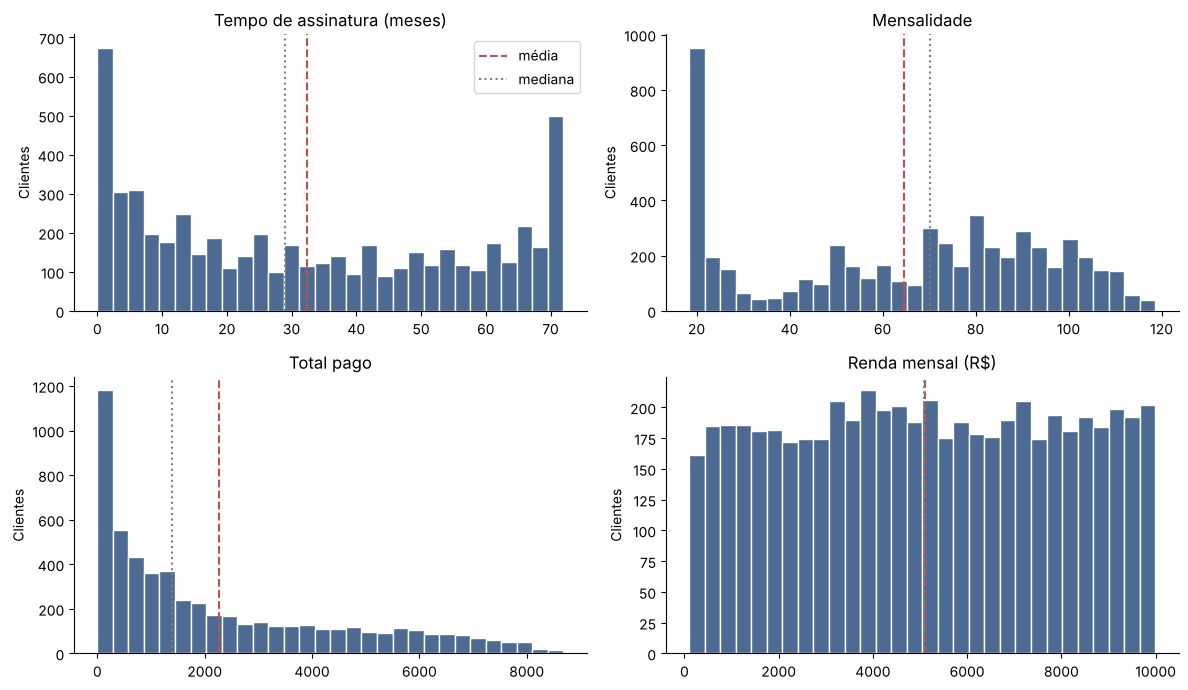

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
titulos = {'Tempo_Assinatura': 'Tempo de assinatura (meses)', 'Valores_Mensais': 'Mensalidade',
           'Valores_Totais': 'Total pago', 'Renda_Mensal': 'Renda mensal (R$)'}
for ax, coluna in zip(axes.flat, numericas):
    ax.hist(df[coluna], bins=30, color=COR_BASE, edgecolor='white')
    ax.axvline(df[coluna].mean(), color=COR_CANCELA, linestyle='--', linewidth=1.5, label='média')
    ax.axvline(df[coluna].median(), color=COR_REFERENCIA, linestyle=':', linewidth=1.5, label='mediana')
    ax.set_title(titulos[coluna])
    ax.set_ylabel('Clientes')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**O que os números mostram:**

- **Tempo de assinatura:** média de 32 meses, mas a distribuição tem dois picos, um de clientes muito novos (até 6 meses) e outro de clientes antigos (perto de 72 meses, o máximo da base). A carteira mistura muita gente recém-chegada com uma base fiel.
- **Mensalidade:** também tem dois grupos. Um pico perto de 20, que são os clientes só com telefone, e uma concentração entre 70 e 100, de quem tem internet. A mediana (70) fica acima da média (65) por causa desse primeiro grupo.
- **Total pago:** assimetria positiva (0,96). Muitos clientes pagaram pouco até agora e poucos pagaram muito. A média (2.272) é bem maior que a mediana (1.391), por isso a mediana representa melhor o cliente típico.
- **Renda mensal:** histograma praticamente plano, com média e mediana iguais e assimetria zero. Isso é uma distribuição uniforme, rara em renda real (que costuma ter muita gente nas faixas baixas e pouca nas altas). É um sinal de que essa coluna foi gerada artificialmente na base fictícia, e por isso ela é tratada com cautela nas Golds.

### Valores extremos

Usamos a regra do intervalo interquartil (IQR): é considerado extremo o valor abaixo de Q1 - 1,5 × IQR ou acima de Q3 + 1,5 × IQR.

In [5]:
extremos = {}
for coluna in numericas:
    q1, q3 = df[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    extremos[coluna] = ((df[coluna] < q1 - 1.5 * iqr) | (df[coluna] > q3 + 1.5 * iqr)).sum()
pd.Series(extremos, name='Valores extremos').to_frame()

,Valores extremos
Tempo_Assinatura,0
Valores_Mensais,0
Valores_Totais,0
Renda_Mensal,0


Nenhuma variável numérica tem valores extremos pela regra do IQR. Não foi preciso tratar outliers na Silver.

## 3. Variáveis categóricas

In [6]:
categoricas = ['Genero', 'Idoso', 'Conjuge', 'Dependentes', 'Servico_Telefonia', 'Varias_Linhas',
               'Servico_Internet', 'Seguranca_Online', 'Backup_Online', 'Protecao_Dispositivos',
               'Suporte_Tecnico', 'Streaming_TV', 'Streaming_Filmes', 'Contrato',
               'Faturamento_Eletronico', 'Forma_Pagamento']

frequencias = []
for coluna in categoricas:
    contagem = df[coluna].replace({True: 'Sim', False: 'Não'}).value_counts()
    for categoria, quantidade in contagem.items():
        frequencias.append({'Variável': coluna, 'Categoria': categoria, 'Clientes': quantidade,
                            '%': round(quantidade / len(df) * 100, 1)})
frequencias = pd.DataFrame(frequencias)
display(frequencias.head(40))

,Variável,Categoria,Clientes,%
0,Genero,Masculino,2835,50.3
1,Genero,Feminino,2798,49.7
2,Idoso,Não,4705,83.5
3,Idoso,Sim,928,16.5
4,Conjuge,Não,2907,51.6
5,Conjuge,Sim,2726,48.4
6,Dependentes,Não,3948,70.1
7,Dependentes,Sim,1685,29.9
8,Servico_Telefonia,Sim,5070,90.0
9,Servico_Telefonia,Não,563,10.0


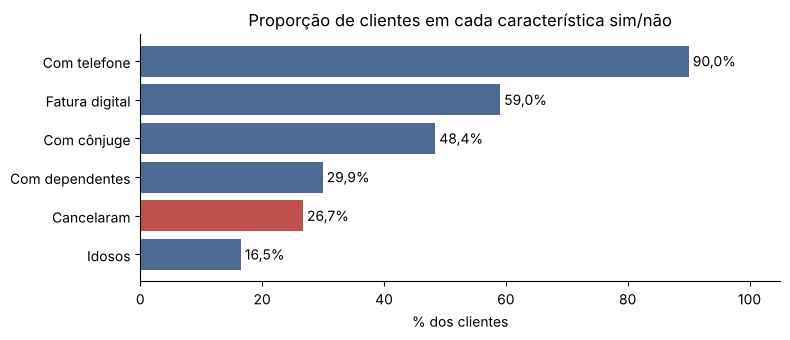

In [7]:
binarias = {'Idoso': 'Idosos', 'Conjuge': 'Com cônjuge', 'Dependentes': 'Com dependentes',
            'Servico_Telefonia': 'Com telefone', 'Faturamento_Eletronico': 'Fatura digital',
            'Status_Cancelamento': 'Cancelaram'}
proporcoes = pd.Series({nome: df[coluna].mean() * 100 for coluna, nome in binarias.items()}).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
cores = [COR_CANCELA if nome == 'Cancelaram' else COR_BASE for nome in proporcoes.index]
barras = ax.barh(proporcoes.index, proporcoes.values, color=cores)
ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in proporcoes.values], padding=3)
ax.set_xlim(0, 105)
ax.set_xlabel('% dos clientes')
ax.set_title('Proporção de clientes em cada característica sim/não')
plt.tight_layout()
plt.show()

**O que os números mostram:**

- A carteira é equilibrada em gênero (50/50) e cônjuge (48% têm).
- Idosos são minoria (16,5%) e só 30% dos clientes têm dependentes.
- Telefone está em 90% da carteira; fatura digital, em 59%.
- **26,7% dos clientes cancelaram.** Essa é a variável que o projeto quer entender e o valor de referência de todas as comparações seguintes.

## 4. Primeira comparação com o cancelamento

### 4.1 Variáveis numéricas: quem cancelou x quem ficou

In [8]:
comparacao = df.groupby('Status_Cancelamento')[numericas].agg(['mean', 'median']).T.round(1)
comparacao.columns = ['Ficou', 'Cancelou']
comparacao

Ficou  Cancelou
Tempo_Assinatura mean      37.4      18.4
                 median    37.0      10.0
Valores_Mensais  mean      61.0      74.6
                 median    64.4      79.8
Valores_Totais   mean    2531.0    1560.8
                 median  1673.6     743.0
Renda_Mensal     mean    5082.0    5167.9
                 median  5048.0    5224.0

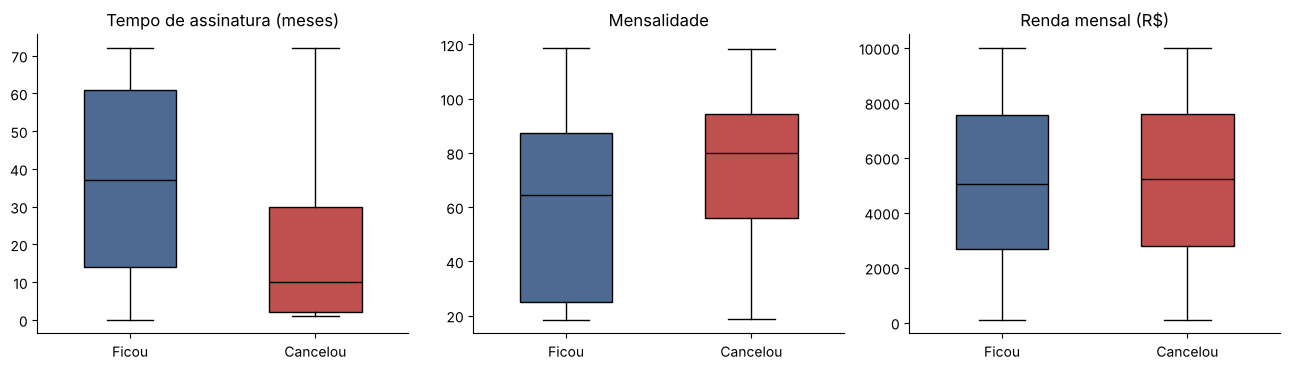

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, coluna in zip(axes, ['Tempo_Assinatura', 'Valores_Mensais', 'Renda_Mensal']):
    dados = [df.loc[~df['Status_Cancelamento'], coluna], df.loc[df['Status_Cancelamento'], coluna]]
    caixa = ax.boxplot(dados, tick_labels=['Ficou', 'Cancelou'], patch_artist=True, widths=0.5,
                       medianprops={'color': 'black'})
    for patch, cor in zip(caixa['boxes'], [COR_BASE, COR_CANCELA]):
        patch.set_facecolor(cor)
    ax.set_title(titulos[coluna])
plt.tight_layout()
plt.show()

- **Tempo de assinatura:** a diferença mais forte. A mediana de quem cancelou é de 10 meses; a de quem ficou, 37.
- **Mensalidade:** quem cancelou pagava mais (mediana de 80 contra 64).
- **Renda:** as caixas são praticamente iguais. A renda não separa quem cancela de quem fica.

### 4.2 Correlação entre as variáveis numéricas

A correlação vai de -1 a 1 e mede o quanto duas variáveis andam juntas em linha reta. Incluímos o cancelamento como 0 (ficou) e 1 (cancelou).

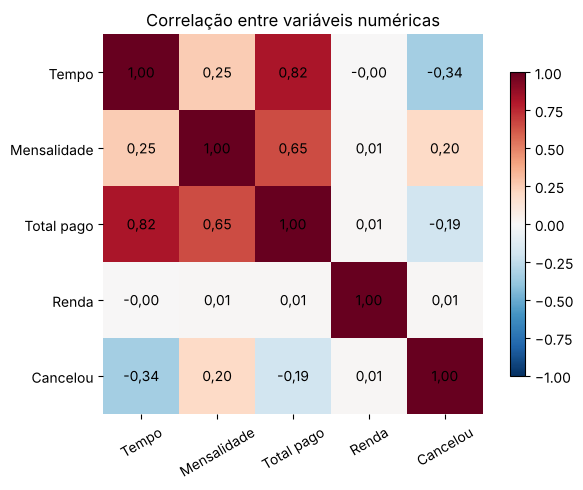

In [10]:
correlacao = df[numericas + ['Status_Cancelamento']].astype(float).corr().round(2)
nomes_curto = ['Tempo', 'Mensalidade', 'Total pago', 'Renda', 'Cancelou']

fig, ax = plt.subplots(figsize=(6.5, 5))
imagem = ax.imshow(correlacao, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(5), nomes_curto, rotation=30)
ax.set_yticks(range(5), nomes_curto)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{correlacao.iloc[i, j]:.2f}'.replace('.', ','), ha='center', va='center', fontsize=10)
fig.colorbar(imagem, ax=ax, shrink=0.8)
ax.set_title('Correlação entre variáveis numéricas')
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

- O cancelamento tem correlação negativa com o tempo de assinatura (-0,34): quanto mais tempo de casa, menor a chance de cancelar.
- Tem correlação positiva fraca com a mensalidade (0,20).
- Com a renda, a correlação é zero.
- Total pago e tempo de assinatura são muito correlacionados (0,82), o que confirma que o total é basicamente tempo × mensalidade. Por isso, nas Golds, usamos tempo e mensalidade em vez do total.

### 4.3 Variáveis categóricas: qual delas mais separa quem cancela?

Para cada variável, calculamos a taxa de cancelamento de cada categoria e a diferença entre a maior e a menor taxa. Quanto maior essa diferença, mais a variável ajuda a separar clientes que cancelam dos que ficam.

Nos serviços adicionais de internet, comparamos só "Sim" e "Não". Se incluíssemos "Sem serviço de internet" (que cancela muito pouco), todos os adicionais pareceriam importantes, inclusive os que não são.

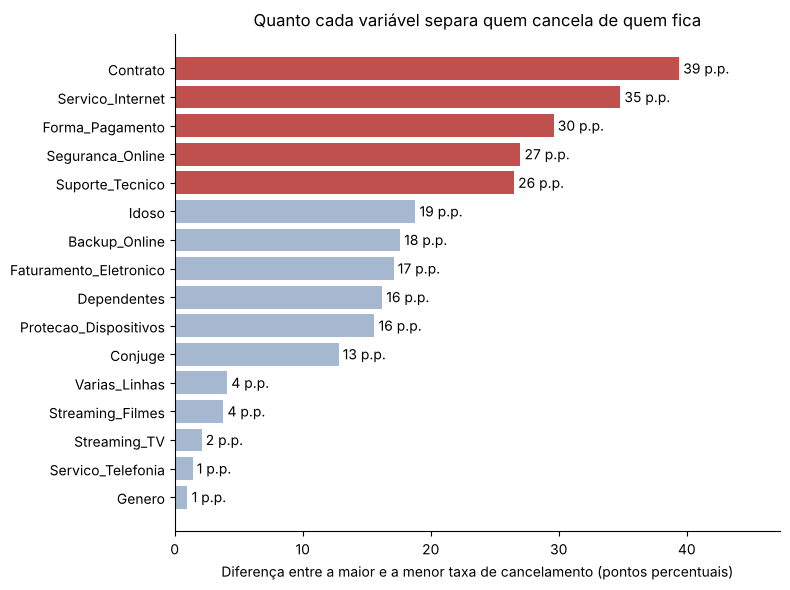

,Diferença (p.p.)
Contrato,39.4
Servico_Internet,34.8
Forma_Pagamento,29.6
Seguranca_Online,27.0
Suporte_Tecnico,26.5
Idoso,18.8
Backup_Online,17.6
Faturamento_Eletronico,17.1
Dependentes,16.2
Protecao_Dispositivos,15.6


In [11]:
diferencas = {}
for coluna in categoricas:
    dados = df[df[coluna] != 'Sem serviço de internet'] if df[coluna].astype(str).str.contains('Sem serviço de internet').any() and coluna != 'Servico_Internet' else df
    taxas = dados.groupby(coluna)['Status_Cancelamento'].mean() * 100
    diferencas[coluna] = taxas.max() - taxas.min()
diferencas = pd.Series(diferencas).sort_values().round(1)

fig, ax = plt.subplots(figsize=(8, 6))
cores = [COR_CANCELA if v >= 20 else '#A5B8D0' for v in diferencas.values]
barras = ax.barh(diferencas.index, diferencas.values, color=cores)
ax.bar_label(barras, labels=[f'{v:.0f} p.p.' for v in diferencas.values], padding=3)
ax.set_xlim(0, diferencas.max() * 1.2)
ax.set_xlabel('Diferença entre a maior e a menor taxa de cancelamento (pontos percentuais)')
ax.set_title('Quanto cada variável separa quem cancela de quem fica')
plt.tight_layout()
plt.show()

diferencas.sort_values(ascending=False).rename('Diferença (p.p.)').to_frame()

**Leitura:** as variáveis que mais separam quem cancela de quem fica (em vermelho, diferença de 20 pontos ou mais) são, nesta ordem, contrato, tipo de internet, forma de pagamento, segurança online e suporte técnico. As características pessoais (idoso, dependentes, cônjuge) vêm num segundo nível. Gênero, telefone e várias linhas quase não fazem diferença.

## Conclusão: o que levar para as Golds

| O que a estatística mostrou | Onde é aprofundado |
|---|---|
| Renda é uniforme e não se relaciona com nada; mensalidade se relaciona com o cancelamento | Gold 1 (Financeiro) |
| Tipo de internet, segurança online e suporte técnico separam bem quem cancela | Gold 2 (Serviços) |
| Contrato, forma de pagamento e tempo de casa são os fatores mais fortes | Gold 3 (Contrato) |
| Gênero não separa quem cancela | Confirmado nas três Golds |

Uma ressalva: estas comparações olham uma variável por vez. Como várias delas andam juntas (por exemplo, contrato mensal e tempo de casa curto), as Golds cruzam as variáveis para entender o que pesa de verdade.